# Importações

In [33]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Diretórios
IMAGES_DIR = Path("../images")
STM32_RESULTS_DIR = Path("../results/stm32")
REFERENCE_DIR = Path("../results/reference")

# Modos disponíveis: "individual" ou "todos"
MODO_TESTE = "individual"

# Configuração explícita dos testes
TESTES = [
    {
        "nome": "Teste barb",
        "original": "barb.pgm",
        "stm32": "barb_result.pgm",
        "referencia": "barbudo.pgm",
    },
]

In [34]:
if not IMAGES_DIR.is_dir():
    raise FileNotFoundError(
        f"Pasta de imagens não encontrada: {IMAGES_DIR.resolve()}"
    )

if not STM32_RESULTS_DIR.is_dir():
    raise FileNotFoundError(
        f"Pasta de resultados da STM32 não encontrada: "
        f"{STM32_RESULTS_DIR.resolve()}"
    )

if not REFERENCE_DIR.is_dir():
    raise FileNotFoundError(
        f"Pasta de referências não encontrada: {REFERENCE_DIR.resolve()}"
    )

imagens_disponiveis = sorted(IMAGES_DIR.glob("*.pgm"))

print(f"Imagens disponíveis: {len(imagens_disponiveis)}")

print("\nResultados da STM32:")
for arquivo in sorted(STM32_RESULTS_DIR.glob("*.pgm")):
    print(f" - {arquivo.name}")

Imagens disponíveis: 2

Resultados da STM32:
 - cameraman_result.pgm
 - pirate_result.pgm


In [30]:
def selecionar_imagens(modo, imagem_escolhida=None):
    imagens = sorted(IMAGES_DIR.glob("*.pgm"))

    if not imagens:
        raise FileNotFoundError(
            f"Nenhuma imagem .pgm encontrada em {IMAGES_DIR.resolve()}"
        )

    if modo == "individual":
        if not imagem_escolhida:
            raise ValueError(
                "Informe IMAGEM_TESTE para executar um teste individual."
            )

        caminho_imagem = IMAGES_DIR / imagem_escolhida

        if not caminho_imagem.is_file():
            raise FileNotFoundError(
                f"Imagem não encontrada: {caminho_imagem.resolve()}"
            )

        return [caminho_imagem]

    elif modo == "todos":
        return imagens

    else:
        raise ValueError(
            "MODO_TESTE deve ser 'individual' ou 'todos'."
        )


imagens_selecionadas = selecionar_imagens(
    MODO_TESTE,
    IMAGEM_TESTE
)

print(f"Modo de teste: {MODO_TESTE}")
print(f"Quantidade de imagens selecionadas: {len(imagens_selecionadas)}")

for imagem in imagens_selecionadas:
    print(f" - {imagem.name}")

Modo de teste: individual
Quantidade de imagens selecionadas: 1
 - cameraman.pgm


# Testes

Função para comparar as imagens:

In [35]:
def comparar_imagens(caminho_original, caminho_stm32, caminho_referencia):
    original = cv2.imread(
        str(caminho_original),
        cv2.IMREAD_GRAYSCALE
    )

    imagem_stm32 = cv2.imread(
        str(caminho_stm32),
        cv2.IMREAD_GRAYSCALE
    )

    referencia = cv2.imread(
        str(caminho_referencia),
        cv2.IMREAD_GRAYSCALE
    )

    if original is None:
        raise ValueError(f"Não foi possível ler: {caminho_original}")

    if imagem_stm32 is None:
        raise ValueError(f"Não foi possível ler: {caminho_stm32}")

    if referencia is None:
        raise ValueError(f"Não foi possível ler: {caminho_referencia}")

    if original.shape != imagem_stm32.shape:
        raise ValueError(
            f"Dimensões diferentes entre original e STM32: "
            f"{original.shape} e {imagem_stm32.shape}"
        )

    if imagem_stm32.shape != referencia.shape:
        raise ValueError(
            f"Dimensões diferentes entre STM32 e referência: "
            f"{imagem_stm32.shape} e {referencia.shape}"
        )

    stm32 = imagem_stm32.astype(np.int16)
    referencia_int = referencia.astype(np.int16)

    diferenca = np.abs(stm32 - referencia_int)

    total_pixels = diferenca.size
    pixels_iguais = int(np.count_nonzero(diferenca == 0))
    pixels_diferentes = total_pixels - pixels_iguais

    percentual_igual = (
        pixels_iguais / total_pixels * 100
        if total_pixels else 0.0
    )

    mae = float(np.mean(diferenca)) if total_pixels else 0.0

    rmse = (
        float(np.sqrt(np.mean(diferenca.astype(np.float64) ** 2)))
        if total_pixels else 0.0
    )

    erro_maximo = int(np.max(diferenca)) if total_pixels else 0

    return {
        "original": original,
        "stm32": imagem_stm32,
        "referencia": referencia,
        "diferenca": diferenca,
        "total_pixels": total_pixels,
        "pixels_iguais": pixels_iguais,
        "pixels_diferentes": pixels_diferentes,
        "percentual_igual": percentual_igual,
        "mae": mae,
        "rmse": rmse,
        "erro_maximo": erro_maximo,
    }

### Tabela com comparação

In [36]:
comparacoes = {}
resultados = []

for caminho_original in imagens_selecionadas:

    nome_imagem = caminho_original.name

    # Exemplo: pirate.pgm -> pirate_result.pgm
    nome_resultado = f"{caminho_original.stem}_result.pgm"

    caminho_stm32 = STM32_RESULTS_DIR / nome_resultado
    caminho_referencia = REFERENCE_DIR / nome_resultado

    # Verifica se os resultados necessários existem.
    arquivos_faltantes = []

    if not caminho_stm32.is_file():
        arquivos_faltantes.append(str(caminho_stm32))

    if not caminho_referencia.is_file():
        arquivos_faltantes.append(str(caminho_referencia))

    if arquivos_faltantes:
        print(f"\nNão foi possível testar {nome_imagem}.")

        for arquivo in arquivos_faltantes:
            print(f"  Arquivo ausente: {arquivo}")

        continue

    # Executa somente a validação, não o algoritmo.
    resultado = comparar_imagens(
        caminho_original,
        caminho_stm32,
        caminho_referencia
    )

    comparacoes[nome_imagem] = resultado

    resultados.append({
        "Imagem": nome_imagem,
        "Pixels iguais": resultado["pixels_iguais"],
        "Pixels diferentes": resultado["pixels_diferentes"],
        "% de igualdade": resultado["percentual_igual"],
        "MAE": resultado["mae"],
        "RMSE": resultado["rmse"],
        "Erro máximo": resultado["erro_maximo"]
    })

if not resultados:
    raise RuntimeError(
        "Nenhuma imagem foi validada. Verifique os resultados da STM32 "
        "e as referências do Kornia."
    )

df_resultados = pd.DataFrame(resultados)

display(df_resultados)

,Imagem,Pixels iguais,Pixels diferentes,% de igualdade,MAE,RMSE,Erro máximo
0,cameraman.pgm,4900,0,100.0,0.0,0.0,0


### Comparação visual

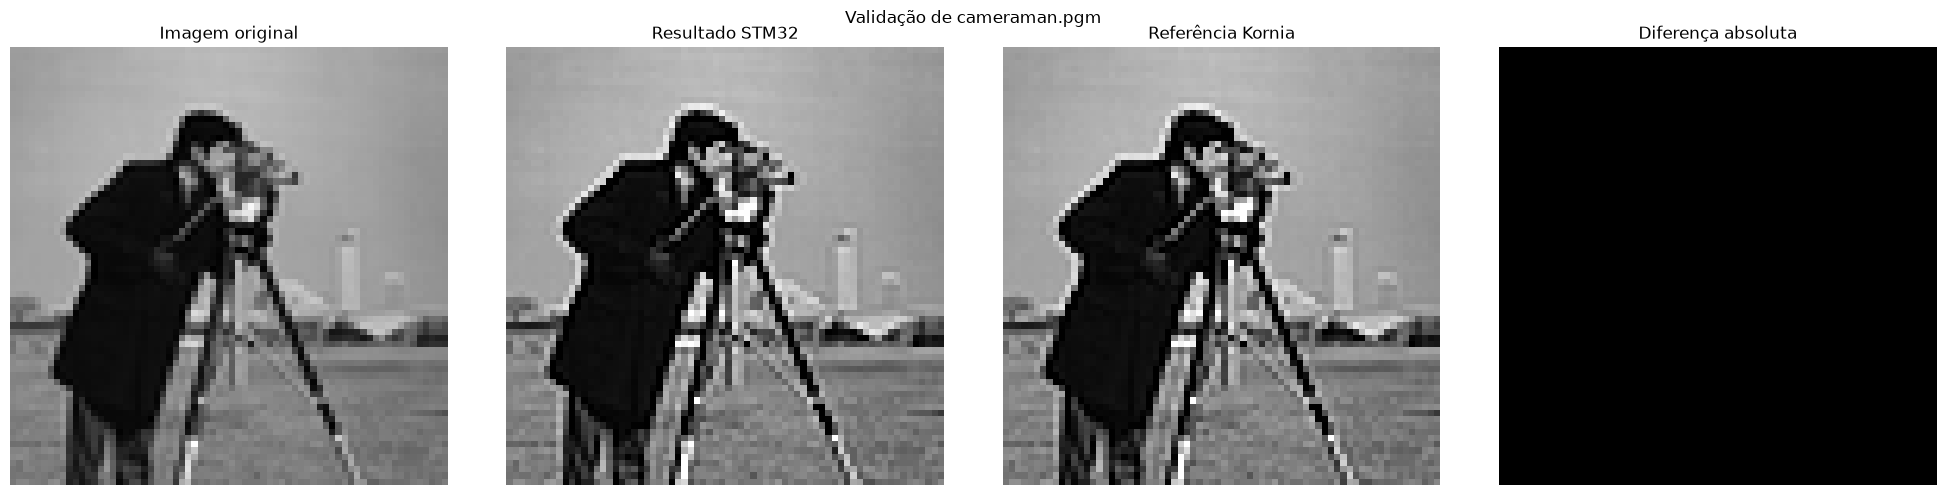

In [21]:
nome_imagem_visual = (
    IMAGEM_TESTE
    if IMAGEM_TESTE in comparacoes
    else next(iter(comparacoes))
)

resultado = comparacoes[nome_imagem_visual]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(
    resultado["original"],
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[0].set_title("Imagem original")

axes[1].imshow(
    resultado["stm32"],
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[1].set_title("Resultado STM32")

axes[2].imshow(
    resultado["referencia"],
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[2].set_title("Referência Kornia")

axes[3].imshow(
    resultado["diferenca"],
    cmap="gray",
    vmin=0,
    vmax=max(1, resultado["erro_maximo"])
)
axes[3].set_title("Diferença absoluta")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"Validação de {nome_imagem_visual}")
plt.tight_layout()
plt.show()

### Resumo

In [24]:
total_imagens = len(comparacoes)

total_pixels = sum(
    resultado["total_pixels"]
    for resultado in comparacoes.values()
)

pixels_iguais = sum(
    resultado["pixels_iguais"]
    for resultado in comparacoes.values()
)

pixels_diferentes = sum(
    resultado["pixels_diferentes"]
    for resultado in comparacoes.values()
)

percentual_global = (
    pixels_iguais / total_pixels * 100
    if total_pixels > 0 else 0
)

imagens_identicas = sum(
    resultado["erro_maximo"] == 0
    for resultado in comparacoes.values()
)

imagens_diferentes = total_imagens - imagens_identicas

maior_erro = max(
    resultado["erro_maximo"]
    for resultado in comparacoes.values()
)

print("=" * 50)
print("RESUMO DA VALIDAÇÃO")
print("=" * 50)

print(f"Modo de teste:             {MODO_TESTE}")
print(f"Imagens validadas:         {total_imagens}")
print(f"Imagens idênticas:         {imagens_identicas}")
print(f"Imagens diferentes:        {imagens_diferentes}")

print()

print(f"Pixels comparados:         {total_pixels}")
print(f"Pixels iguais:             {pixels_iguais}")
print(f"Pixels diferentes:         {pixels_diferentes}")
print(f"Percentual de igualdade:   {percentual_global:.4f}%")
print(f"Maior erro encontrado:     {maior_erro}")

print("=" * 50)

RESUMO DA VALIDAÇÃO
Modo de teste:             todos
Imagens validadas:         2
Imagens idênticas:         2
Imagens diferentes:        0

Pixels comparados:         9800
Pixels iguais:             9800
Pixels diferentes:         0
Percentual de igualdade:   100.0000%
Maior erro encontrado:     0
